# Phasenrekonstruktion mit der Transport-of-Intensity-Gleichung (TIE)

Kameras messen nur Intensitäten. Ein durchsichtiges Objekt (z.B. eine Zelle
oder eine Glasstruktur) ändert aber fast nur die Phase und ist im Fokus
praktisch unsichtbar. Defokussiert man ein wenig, wird es sichtbar: Phasengradienten
lenken Licht um, gekrümmte Phase sammelt oder zerstreut es wie eine Linse. Die
**Transport-of-Intensity-Gleichung** beschreibt das quantitativ:

$$k\,\frac{\partial I}{\partial z} = -\nabla_\perp\cdot\big(I\,\nabla_\perp\varphi\big).$$

Aus zwei leicht defokussierten Bildern erhält man $\partial I/\partial z$ und kann
die Gleichung (eine Poisson-Gleichung) nach der Phase $\varphi$ auflösen.
`pyoptics.TIE` stellt dafür `tie()` (Vorwärtsrichtung), `solve_tie()`
(Lösung per FFT) und `enhanced_tie_solve()` (iterative Verbesserung) bereit.

**Konvention:** $\exp(i(kz - \omega t))$, das Feld ist $\sqrt{I}\,e^{i\varphi}$. Eine
konvergierende Welle (Phase fällt nach außen ab, wie hinter einer Sammellinse)
hat auf der Achse $\partial I/\partial z > 0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import TIE
from pyoptics.utils import grid2d, get_z_derivative

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 0.5
k = 2*np.pi/wl

## 1. Ein Phasenobjekt

Zwei Gauß-förmige Phasenbuckel (einer positiv, einer negativ) in einem breiten
Gauß-Strahl. Die Intensität im Fokus enthält keine Spur des Objekts.

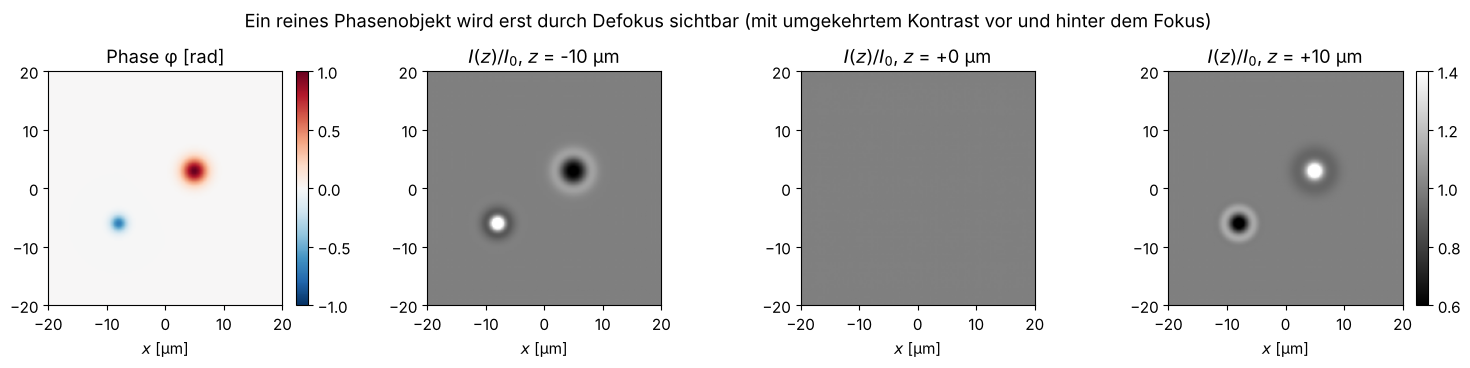

In [2]:
L, N = 60.0, 256
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
phase = 1.0*np.exp(-((X - 5)**2 + (Y - 3)**2)/(2*1.5**2)) - 0.7*np.exp(-((X + 8)**2 + (Y + 6)**2)/(2*1.0**2))
I0 = np.exp(-(X**2 + Y**2)/(2*20**2))
U0 = np.sqrt(I0)*np.exp(1j*phase)

def intensity_at(z):
    """Intensität nach Propagation um z. Für z < 0 per Zeitumkehr (siehe Notebook 05),
    damit Rundungsfehler in evaneszenten Frequenzen nicht explodieren."""
    if z >= 0:
        return np.abs(TIE.field_prop(U0, x, y, z, wl))**2
    return np.abs(TIE.field_prop(np.conj(U0), x, y, -z, wl))**2

ext = (x[0], x[-1], y[0], y[-1])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
im = axes[0].imshow(phase, extent=ext, cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], fraction=0.046); axes[0].set_title("Phase φ [rad]")
for ax, z in zip(axes[1:], (-10, 0, 10)):
    I = intensity_at(z)
    im = ax.imshow(I/I0, extent=ext, cmap="gray", vmin=0.6, vmax=1.4)
    ax.set_title(f"$I(z)/I_0$, $z$ = {z:+d} µm")
fig.colorbar(im, ax=axes[3], fraction=0.046)
for ax in axes:
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_xlabel("$x$ [µm]")
fig.suptitle("Ein reines Phasenobjekt wird erst durch Defokus sichtbar (mit umgekehrtem Kontrast vor und hinter dem Fokus)")
fig.tight_layout()

Der positive Phasenbuckel wirkt wie eine Sammellinse (für $z > 0$ hell), der
negative wie eine Zerstreuungslinse (dunkel). Vor dem Fokus ist es umgekehrt.

## 2. Vorwärtsrichtung: Stimmt die TIE?

`TIE.tie(phase, I, x, y, lam)` berechnet $\partial I/\partial z$ aus der Phase. Zum
Vergleich der zentrale Differenzenquotient aus zwei propagierten Bildern.

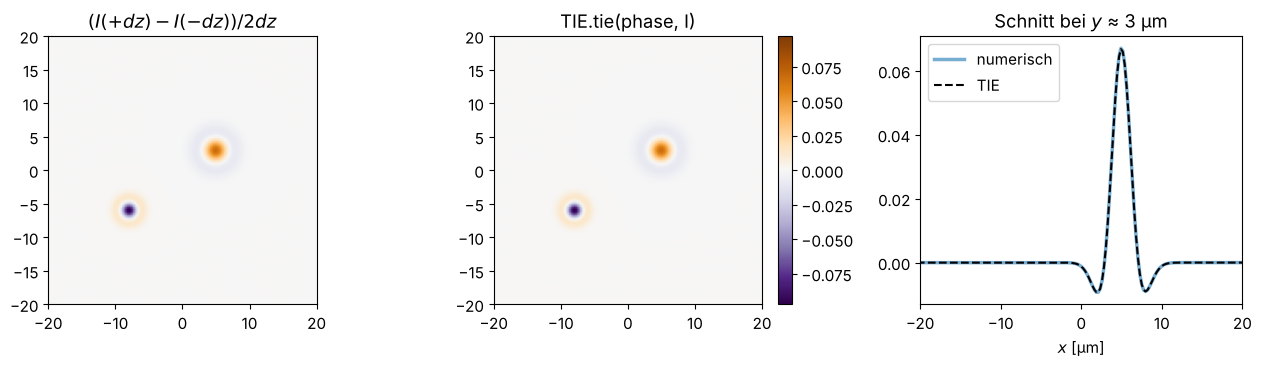

In [3]:
dz = 1.0
dIdz_num = (intensity_at(dz) - intensity_at(-dz))/(2*dz)
dIdz_tie = TIE.tie(phase, I0, x, y, wl)
vmax = np.abs(dIdz_tie).max()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, D, title in zip(axes[:2], (dIdz_num, dIdz_tie), ("$(I(+dz) - I(-dz))/2dz$", "TIE.tie(phase, I)")):
    im = ax.imshow(D, extent=ext, cmap="PuOr_r", vmin=-vmax, vmax=vmax)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_title(title)
fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].plot(x, dIdz_num[N//2 + int(3/(x[1]-x[0]))], lw=2.5, alpha=0.6, label="numerisch")
axes[2].plot(x, dIdz_tie[N//2 + int(3/(x[1]-x[0]))], "k--", label="TIE")
axes[2].set_xlim(-20, 20); axes[2].set_xlabel("$x$ [µm]"); axes[2].legend(); axes[2].set_title("Schnitt bei $y$ ≈ 3 µm")
fig.tight_layout()

## 3. Rückwärtsrichtung: Phase aus zwei Bildern

`solve_tie(I, dI_dz, x, y, lam, alpha)` löst die TIE mit zwei inversen
Laplace-Operatoren im Fourier-Raum. Die Phase ist nur bis auf eine Konstante
bestimmt; für den Vergleich ziehen wir jeweils den Mittelwert im beleuchteten
Bereich ab.

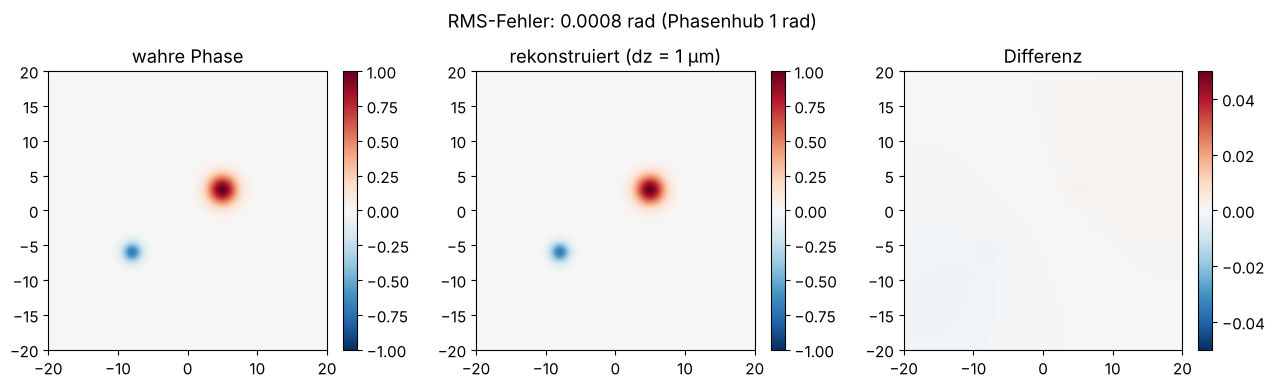

In [4]:
mask = I0 > 0.2
def rms_error(ph):
    e = (ph - phase)[mask]
    return np.sqrt(np.mean((e - e.mean())**2))

phase_rec = TIE.solve_tie(I0, dIdz_num, x, y, wl, 0.0)
offset = np.mean((phase_rec - phase)[mask])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, P, title in zip(axes, (phase, phase_rec - offset, phase_rec - offset - phase),
                        ("wahre Phase", "rekonstruiert (dz = 1 µm)", "Differenz")):
    lim = 1 if title != "Differenz" else 0.05
    im = ax.imshow(np.where(mask, P, np.nan), extent=ext, cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20); ax.set_title(title)
fig.suptitle(f"RMS-Fehler: {rms_error(phase_rec):.4f} rad (Phasenhub 1 rad)")
fig.tight_layout()

## 4. Der Kompromiss beim Defokus-Abstand

In der Praxis sind die Bilder verrauscht. Der Differenzenquotient
$(I_+ - I_-)/2\Delta z$ verstärkt das Rauschen um $1/\Delta z$: Kleine Abstände sind
empfindlich gegen Rauschen. Große Abstände verletzen dagegen die Annahme, dass
sich $I$ linear mit $z$ ändert (Beugung "verschmiert" die feinen Strukturen).
Dazwischen liegt ein Optimum, das vom Rauschpegel abhängt.

Der zweite Parameter ist die **Regularisierung** `alpha`: Der inverse Laplace-Operator
$-1/(k_x^2 + k_y^2)$ verstärkt niedrige Frequenzen und damit niederfrequentes
Rauschen. Mit `alpha > 0` wird er zu $-1/(k_x^2 + k_y^2 + \alpha)$ gedämpft.

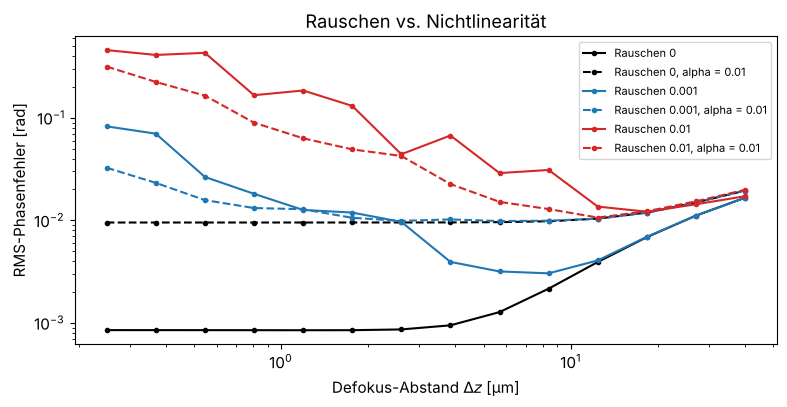

In [5]:
rng = np.random.default_rng(0)
dz_vals = np.logspace(np.log10(0.25), np.log10(40), 14)
noise_levels = (0.0, 1e-3, 1e-2)
fig, ax = plt.subplots(figsize=(8, 4.2))
for noise, c in zip(noise_levels, ("k", "C0", "C3")):
    for alpha, ls in ((0.0, "-"), (1e-2, "--")):
        errs = []
        for dz in dz_vals:
            Ip = intensity_at(dz) + noise*rng.standard_normal(X.shape)
            Im = intensity_at(-dz) + noise*rng.standard_normal(X.shape)
            errs.append(rms_error(TIE.solve_tie(I0, (Ip - Im)/(2*dz), x, y, wl, alpha)))
        label = f"Rauschen {noise:g}" + (f", alpha = {alpha:g}" if alpha else "")
        ax.loglog(dz_vals, errs, ls, color=c, marker="o", ms=3, label=label)
ax.set_xlabel("Defokus-Abstand $\\Delta z$ [µm]"); ax.set_ylabel("RMS-Phasenfehler [rad]")
ax.set_title("Rauschen vs. Nichtlinearität"); ax.legend(fontsize=8)
fig.tight_layout()

## 5. Mehr Ebenen: Savitzky-Golay-Ableitung

Mit mehr als zwei Bildern lässt sich die Ableitung robuster schätzen.
`utils.get_z_derivative(stack, dz, order)` passt pro Pixel ein Polynom an
die Intensität entlang $z$ an (Savitzky-Golay) und wertet dessen Ableitung in
der mittleren Ebene aus. Mehr Ebenen im selben $z$-Bereich mitteln das Rauschen
heraus. Ein höherer Polynomgrad würde den systematischen Fehler durch die
Nichtlinearität verringern, verstärkt aber wieder das Rauschen; in diesem
rauschdominierten Fall ist die Gerade (Grad 1) am besten.

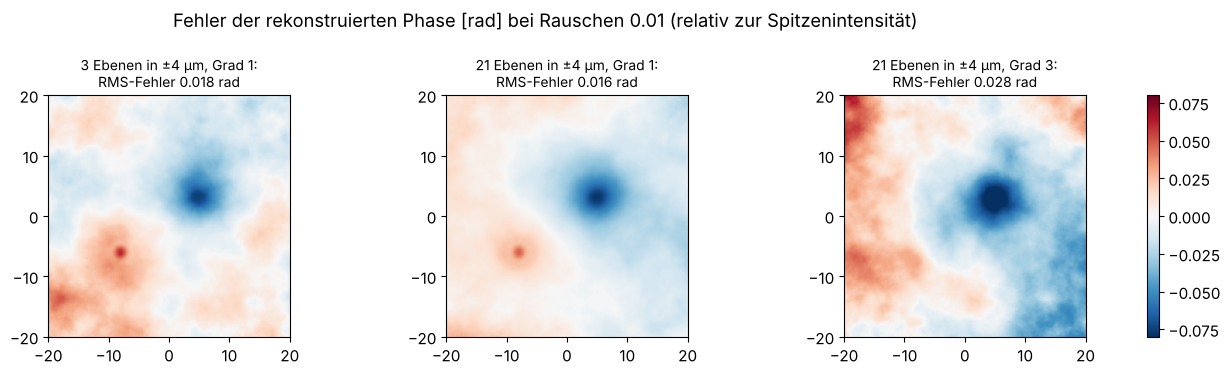

In [6]:
noise = 1e-2
z_max = 4.0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
results = {}
for n_planes, order in ((3, 1), (21, 1), (21, 3)):
    z_planes = np.linspace(-z_max, z_max, n_planes)
    stack = np.dstack([intensity_at(z) + noise*rng.standard_normal(X.shape) for z in z_planes])
    dIdz = get_z_derivative(stack, z_planes[1] - z_planes[0], order)
    results[(n_planes, order)] = TIE.solve_tie(I0, dIdz, x, y, wl, 1e-2)
for ax, ((n_planes, order), ph) in zip(axes, results.items()):
    err = ph - phase - np.mean((ph - phase)[mask])
    im = ax.imshow(np.where(mask, err, np.nan), extent=ext, cmap="RdBu_r", vmin=-0.08, vmax=0.08)
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)
    ax.set_title(f"{n_planes} Ebenen in ±{z_max:.0f} µm, Grad {order}:\nRMS-Fehler {rms_error(ph):.3f} rad", fontsize=10)
fig.suptitle(f"Fehler der rekonstruierten Phase [rad] bei Rauschen {noise} (relativ zur Spitzenintensität)")
fig.tight_layout()
fig.colorbar(im, ax=axes, fraction=0.02)

## 6. Iterative Verbesserung

`enhanced_tie_solve()` berechnet nach der ersten Lösung das Residuum
$\partial_z I - \mathrm{TIE}(\varphi)$, löst die TIE dafür erneut und addiert die
Korrektur. Das hilft, wenn die Intensität stark ungleichmäßig ist, denn
`solve_tie()` verwendet eine Näherung für den Term mit $1/I$. Wir testen das mit
einer stark strukturierten Beleuchtung.

Enanced TIE iteration 1
Enanced TIE iteration 2
Enanced TIE iteration 3
Enanced TIE iteration 4
Enanced TIE iteration 5


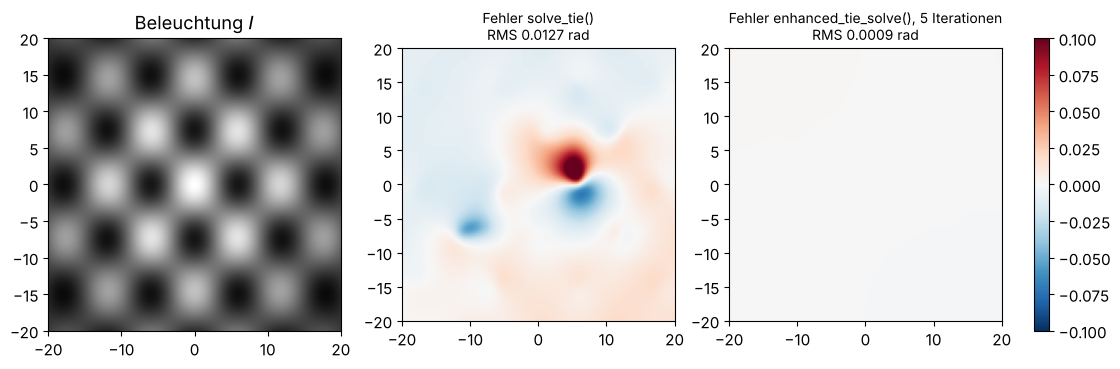

In [7]:
I_struct = I0*(0.55 + 0.45*np.cos(2*np.pi*X/12)*np.cos(2*np.pi*Y/15))
dIdz_struct = TIE.tie(phase, I_struct, x, y, wl)
ph0 = TIE.solve_tie(I_struct, dIdz_struct, x, y, wl, 0.0)
ph_enh = TIE.enhanced_tie_solve(5, I_struct, dIdz_struct, x, y, wl, 0.0, true_phase=None)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(I_struct, extent=ext, cmap="gray"); axes[0].set_title("Beleuchtung $I$")
for ax, ph, title in zip(axes[1:], (ph0, ph_enh), ("solve_tie()", "enhanced_tie_solve(), 5 Iterationen")):
    err = np.where(mask, ph - phase - np.mean((ph - phase)[mask]), np.nan)
    im = ax.imshow(err, extent=ext, cmap="RdBu_r", vmin=-0.1, vmax=0.1)
    ax.set_title(f"Fehler {title}\nRMS {rms_error(ph):.4f} rad", fontsize=10)
fig.colorbar(im, ax=axes[1:], fraction=0.03)
for ax in axes:
    ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)